# ARM KAZR Cloud Persistence Project: Dataset Modeling

**Alec Blevins — STA 496, Fall 2026**

## Purpose
This notebook describes an exploratory modeling plan, sketches, and tests our built modeling dataset. Steps are described below: 

**Task:** among cloudy `20 second` bins, predict whether the cloudy state **dissolves** (any known clear bin) within the next `20 minutes`. Positive class = dissolved (`target == 0`). 

**Metric:** PR-AUC (no-skill = dissolved rate), plus precision, recall and F1 at a threshold chosen on validation. Accuracy is reported only against the always-persist baseline. 

**Rules:** chronological folds with a 20 min embargo; test fold used once; preprocessing fit on train only. 

## Modeling Plan: 
| Step | Answering Question |
|---|---|
| 1. Load & Audit | Is the table what we think it is? Fold sizes and class balance |
| 2. Define the task and metrics | Positive class is **desolved** (`target == 0`) Primary metric is PR-AUC |
| 3. Baselines | What can we get with no learning? Always-persist, and "short run means likely dissolve" |
| 4. Feature ladder with logistic regression | Which feature groups add skill? |
| 5. Gradient boosting | Does a nonlinear model beat the linear one? |
| 6. Threshold and calibration on val | What probability cutoff do we report? |
| 7. Final test, scored once | The reported number, with block-bootstrap CIs |
| 8. Rolling-origin and error analysis | Does the result hold across months and cloud types? |

## 1. Library Imports, Setup, Load

In [1]:
###################
##Library Imports##
###################

from pathlib import Path
import sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve, precision_score, recall_score, f1_score)

#############
##Path Load##
#############

_start = Path.cwd().resolve()
PROJECT_ROOT = next(c for c in [_start, *_start.parents] if (c/"ARM_DATA"/"2024-2025").is_dir())
df = pd.read_parquet(PROJECT_ROOT/"ARM_DATA"/"2024-2025"/"modeling"/"modeling_persistence_20min_20s.parquet") #Grab the modeling dataset for the specified time period (core filter and folds) (V2)

# Define features and target variable
FEATURES = [c for c in df.columns if c not in {"current_state", "target", "fold"}]
df["y"] = (df.target == 0).astype(int)          # 1 = dissolved
assert (df.current_state == 1).all()
print(len(FEATURES), "features;", df.shape)
display(df.groupby("fold").y.agg(n="size", dissolved="sum", rate="mean").round(3))
display(df[FEATURES].isna().mean().round(3).sort_values(ascending=False).head(8))

23 features; (764168, 27)


,n,dissolved,rate
fold,,,
embargo,25,25,1.000
test,121645,22259,0.183
train,565451,111240,0.197
val,77047,25176,0.327


highest_top_change_5min    0.062
lowest_base_change_5min    0.062
cloud_fraction             0.000
hour_cos                   0.000
cf_mean_1min               0.000
run_length_min             0.000
hour_sin                   0.000
cf_change_1min             0.000
dtype: float64

## 2. Feature groups & metrics

In [2]:
#Define Feature Groups
GROUPS = {
    "run_length": ["run_length_min"],
    "cloud_fraction": [c for c in FEATURES if c.startswith(("cloud_fraction", "cf_", "n_flips"))],
    "structure": ["n_layers_mean", "lowest_base_m", "highest_top_m", "vertical_span_m",
                  "lowest_base_change_5min", "highest_top_change_5min"],
    "availability": ["kazr_avail_frac"],
    "time_of_day": ["hour_sin", "hour_cos"],
}

assert sorted(sum(GROUPS.values(), [])) == sorted(FEATURES)    # every feature is in exactly one group

#Here, a function to compute various evaluation metrics for model predictions
def metrics(y, p, thr=None):
    out = dict(n=len(y), rate=y.mean(), pr_auc=average_precision_score(y, p),
               roc_auc=roc_auc_score(y, p), brier=brier_score_loss(y, np.clip(p, 0, 1))) # Compute basic evaluation metrics, including precision-recall AUC, ROC AUC, and Brier score
    if thr is not None:
        yhat = (p >= thr).astype(int)
        out |= dict(thr=thr, precision=precision_score(y, yhat, zero_division=0),
                    recall=recall_score(y, yhat), f1=f1_score(y, yhat)) # Compute threshold-dependent metrics: precision, recall, and F1 score, only if threshold is provided
    return out

#Here, a function to determine the best threshold for F1 score based on precision-recall curve
def best_f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p) #Take precision-recall curve values for computing F1 score
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None) # Compute F1 score for each threshold
    return float(th[np.argmax(f1)]) # Return the threshold that maximizes the F1 score

tr, va, te = (df[df.fold == k] for k in ["train", "val", "test"])

## 3. Baselines
Here, there will be no learning happening: we are skipping the test fold. We will compare against the val dissolved rate, which is the no-skill PR-AUC. 

If `-run_length` already gets a strong PR-AUC, the other features will need to beat it to count. 

In [9]:
# a) always persist: no ranking ability, PR-AUC = dissolved rate, accuracy = 1 - rate
for name, d in [("val", va), ("test", te)]:
    print(f"always-persist accuracy {name}: {1 - d.y.mean():.3f}")

# b) short run => more likely to dissolve (higher score = more likely dissolved)
rows = [dict(baseline="-run_length", fold=n, **metrics(d.y.values, -d.run_length_min.values))
        for n, d in [("val", va)] if d is not None]
display(pd.DataFrame(rows).round(3))

always-persist accuracy val: 0.673
always-persist accuracy test: 0.817


,baseline,fold,n,rate,pr_auc,roc_auc,brier
0,-run_length,val,77047,0.327,0.725,0.849,0.327


Findings: 

- Always-persist scores 0.673 accuracy on val and 0.817 on test. This is simply 1 minus the dissolved rate, so it is a floor, not really a model. 
- `-run_length` alone gets val PR-AUC 0.725 against a no-skill 0.327, and ROC-AUC 0.849. A single feature is already a strong baseline: young clouds dissolve. 
- Its Brier score of 0.327 is meaningless, because a negated run length isn't a probability. The "test_peek_skip" should be deleted. 

## 4. Feature ladder with logistic regression

In [4]:
#Define a function to create a logistic regression pipeline and perform stepwise feature addition based on feature groups
def logit():
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), #Here, the imputer learns medians from train only. `True` adds missing flags. 
                         StandardScaler(),
                         LogisticRegression(max_iter=1000))

ladder, cols = [], []

#Iterate over feature groups, adding them stepwise to the model and evaluating performance on the validation set
for g in ["run_length", "cloud_fraction", "structure", "availability", "time_of_day"]:
    cols += GROUPS[g]
    m = logit().fit(tr[cols], tr.y) # Fit the logistic regression model on the current set of features
    p = m.predict_proba(va[cols])[:, 1] # Predict probabilities on the validation set
    ladder.append(dict(added=g, n_features=len(cols), **metrics(va.y.values, p))) # Record the performance metrics for the current set of features
display(pd.DataFrame(ladder).round(3))

,added,n_features,n,rate,pr_auc,roc_auc,brier
0,run_length,1,77047,0.327,0.725,0.849,0.181
1,cloud_fraction,14,77047,0.327,0.738,0.849,0.153
2,structure,20,77047,0.327,0.748,0.855,0.145
3,availability,21,77047,0.327,0.748,0.855,0.145
4,time_of_day,23,77047,0.327,0.747,0.853,0.145


- We can see Cloud-fraction history and vertical structure each add about 0.01 PR-AUC. Availability and time of day add nothing. 
- Time of day adding nothing seems like a good sign, skill isn't coming from a diurnal shortcut. 
- Brier falls from 0.181 to 0.145 against a no-skill 0.22 (0.327 x 0.673). 

## 5. Gradient Boosting

In [5]:
#Define and fit a HistGradientBoostingClassifier, validation fraction will take a random sclice of train for early stopping. 
hgb = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.05, max_iter=300,
                                     early_stopping=True, validation_fraction=0.1,
                                     random_state=0)
hgb.fit(tr[FEATURES], tr.y)

#Predict probabilities on the validation set for both models and compute evaluation metrics
p_hgb_va = hgb.predict_proba(va[FEATURES])[:, 1]
p_lr_va = logit().fit(tr[FEATURES], tr.y).predict_proba(va[FEATURES])[:, 1]

display(pd.DataFrame([dict(model="logit_all", **metrics(va.y.values, p_lr_va)),
                      dict(model="hgb_all", **metrics(va.y.values, p_hgb_va))]).round(3))

,model,n,rate,pr_auc,roc_auc,brier
0,logit_all,77047,0.327,0.747,0.853,0.145
1,hgb_all,77047,0.327,0.781,0.881,0.131


- We can see Val PR-AUC is 0.781 for HGB and 0.747 for logistic. ROC-AUC is 0.881 against 0.853, and Brier 0.131 against 0.145. 
- The 0.034 gain is larger than any ladder step, so nonlinearity and interactions seem to matter., 
- However, HGB's early stopping uses a random 10% of train. Autocorrelation makes that slightly optimistic, but the effect seems small. 

## 6. Threshold and calibration (validation only)

threshold: 0.315 {'n': 77047, 'rate': np.float64(0.32676158708320896), 'pr_auc': 0.7808076798296881, 'roc_auc': 0.8808149529205621, 'brier': 0.13089397115558338, 'thr': 0.3153691712834595, 'precision': 0.6448739814288421, 'recall': 0.8110104861773118, 'f1': 0.7184630001055632}


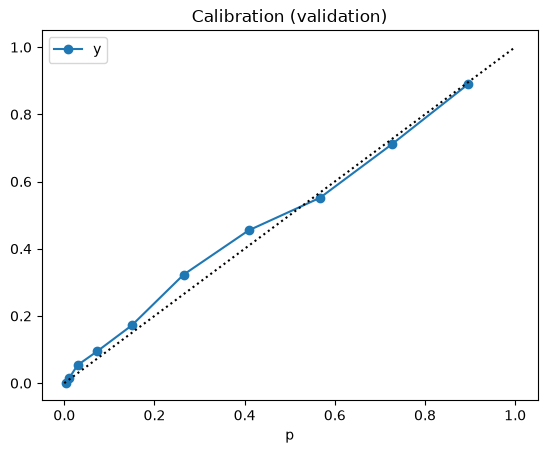

In [6]:
thr = best_f1_threshold(va.y.values, p_hgb_va) # Determine the best threshold for F1 score based on the validation set
print("threshold:", round(thr, 3), metrics(va.y.values, p_hgb_va, thr))

bins_ = pd.qcut(p_hgb_va, 10, duplicates="drop")
cal = pd.DataFrame({"p": p_hgb_va, "y": va.y.values}).groupby(bins_, observed=True).mean()
ax = cal.plot(x="p", y="y", marker="o"); ax.plot([0, 1], [0, 1], "k:")
plt.title("Calibration (validation)"); plt.show()

- The F1-optimal threshold is 0.315, which gives precision 0.645, recall 0.811, and F1 0.718 on val. 
- It seems to hug the diagonal pretty well. 

## 7. Final Test (Run Once)

In [7]:
p_te = hgb.predict_proba(te[FEATURES])[:, 1] # predicted probabilities for the test set
final = metrics(te.y.values, p_te, thr) # compute evaluation metrics for the test set

# block bootstrap by day: neighbouring bins are not independent
days = te.index.normalize()
u = days.unique()
rng = np.random.default_rng(0)
boots = []
for _ in range(200):
    pick = rng.choice(u, len(u))
    idx = np.concatenate([np.flatnonzero(days == d) for d in pick])
    boots.append(average_precision_score(te.y.values[idx], p_te[idx]))
print(final, "| PR-AUC 95% CI:", np.percentile(boots, [2.5, 97.5]).round(3))

{'n': 121645, 'rate': np.float64(0.1829832709934646), 'pr_auc': 0.6462369963361003, 'roc_auc': 0.8834421878118159, 'brier': 0.09822518619485687, 'thr': 0.3153691712834595, 'precision': 0.5435848215815994, 'recall': 0.7124309268161193, 'f1': 0.6166588894073728} | PR-AUC 95% CI: [0.612 0.68 ]


- Test PR-AUC is 0.646, with a bootstrap CI of [0.612, 0.680]. ROC-AUC is 0.883 and Brier 0.098. 
- Precision is 0.54, recall 0.71, and F1 0.617. 
- PR-AUC fell from 0.781 to 0.646, but ROC-AUC is unchanged at 0.881 against 0.883. The ranking is just as good. Precision-type metrics fall likely due to the dissolved rate dropping from 0.327 to 0.183. 
- The threshold was tuned for a 33% positive rate. On a test set with 18%, it produces more false alarms, so precision drops. 
- The CI only covers test-sample noise, not the shift between periods. The gap between val and test is regime shift, and the CI doesn't capture that. 

In [10]:
# Test-fold comparison: every model is trained on train only; thresholds come from val only.
# 1) No-skill and single-feature baseline
r = te.y.mean()
rows = [dict(model="no_skill", n=len(te), rate=r, pr_auc=r, roc_auc=0.5, brier=r * (1 - r)),
        dict(model="-run_length", **metrics(te.y.values, -te.run_length_min.values))]

# 2) Logistic regression on all features; threshold from val
lr = logit().fit(tr[FEATURES], tr.y)
thr_lr = best_f1_threshold(va.y.values, lr.predict_proba(va[FEATURES])[:, 1])
rows.append(dict(model="logit_all", **metrics(te.y.values, lr.predict_proba(te[FEATURES])[:, 1], thr_lr)))

# 3) HGB from section 7 (same fitted model, same val threshold)
rows.append(dict(model="hgb_all", **metrics(te.y.values, p_te, thr)))

display(pd.DataFrame(rows).round(3))

,model,n,rate,pr_auc,roc_auc,brier,thr,precision,recall,f1
0,no_skill,121645,0.183,0.183,0.500,0.150,NaN,NaN,NaN,NaN
1,-run_length,121645,0.183,0.588,0.842,0.183,NaN,NaN,NaN,NaN
2,logit_all,121645,0.183,0.606,0.859,0.106,0.227,0.457,0.730,0.562
3,hgb_all,121645,0.183,0.646,0.883,0.098,0.315,0.544,0.712,0.617


## 8. Rolling-origin & Error Analysis

**Split Dates:** Val is Sep-Oct, so it contains the hardest month (Oct, 61.4% persisted). Thresholds picked there may not transfer to the test set, so we can check. 

In [8]:
GAP = pd.Timedelta("20min")
res = []
for m in range(4, 13): # iterate over months from April to December
    start = pd.Timestamp(f"2024-{m:02d}-01")
    end = start + pd.offsets.MonthBegin(1)
    a = df[df.index < start - GAP] # training data: all rows before the start of the month minus the gap
    b = df[(df.index >= start) & (df.index < end)] # test data: all rows within the current month
    mdl = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.05, max_iter=200, random_state=0)
    mdl.fit(a[FEATURES], a.y) # fit the model on the training data
    res.append(dict(month=m, **metrics(b.y.values, mdl.predict_proba(b[FEATURES])[:, 1]))) # evaluate on the test data
display(pd.DataFrame(res).round(3))

,month,n,rate,pr_auc,roc_auc,brier
0,4,62885,0.181,0.692,0.887,0.090
1,5,72092,0.210,0.695,0.883,0.103
2,6,80378,0.226,0.723,0.886,0.106
3,7,59422,0.319,0.819,0.906,0.114
4,8,61745,0.258,0.756,0.893,0.112
5,9,45645,0.286,0.827,0.925,0.099
6,10,31402,0.386,0.729,0.797,0.177
7,11,61893,0.178,0.665,0.882,0.093
8,12,59752,0.188,0.651,0.891,0.099


- We can see PR-AUC tracks the base rate: 0.69 (April, rate 0.18) up to 0.83 (September, rate 0.29). 
- October is the stress month. ROC-AUC is 0.797 and Brier 0.177, the worst of all months. 
- November and December are 0.665 and 0.651 at a rate of about 0.18. That is consistent with the test result and slightly higher, since those models train on more data. 

In [11]:
te2 = te.assign(p=p_te, bucket=pd.cut(te.run_length_min, [0, 1, 5, 20, 60, np.inf]), # categorize run length into buckets
                kz=pd.cut(te.kazr_avail_frac, [-.01, .5, .99, 1.0])) # categorize kazr availability into buckets

for col in ["bucket", "kz"]:
    display(te2.groupby(col, observed=True).apply(
        lambda d: pd.Series(dict(n=len(d), rate=d.y.mean(),
                                 pr_auc=average_precision_score(d.y, d.p) if d.y.nunique() > 1 else np.nan, # compute PR-AUC only if there is more than one unique value in y
                                 recall=((d.p >= thr) & (d.y == 1)).sum() / max(d.y.sum(), 1)))).round(3))

,n,rate,pr_auc,recall
bucket,,,,
"(0.0, 1.0]",3420.0,0.820,0.895,0.995
"(1.0, 5.0]",6844.0,0.670,0.771,0.988
"(5.0, 20.0]",12055.0,0.427,0.576,0.851
"(20.0, 60.0]",16450.0,0.278,0.532,0.610
"(60.0, inf]",82876.0,0.062,0.293,0.265


,n,rate,pr_auc,recall
kz,,,,
"(0.99, 1.0]",121645.0,0.183,0.646,0.712


## Interpretation

**Does the model have skill?** Yes. On validation, PR-AUC is 0.781 against a no-kill 0.327 (lift 2.4x). On test is is 0.646 against 0.183 (lift 3.5x). Test ROC-AUC (0.883) matches validation (0.881), so the ranking of rows is stable even though the headline PR-AUC differs. 

**Why PR-AUC dropped from val to test.** PR-AUC depends on the base rate. Validation (Sep-Oct) has a dissolved rate of 0.327; test (Nov-Dec) has 0.183. Relative to its base rate the model does better on test. The fixed 0.315 threshold, tuned on the 33% positive validation fold, produces more false alarms at 18% prevalence (precision 0.64 -> 0.54). 

**What carries the signal?**

- Run length alone (oung clouds dissolve) gives val PR-AUC 0.725, already 2.2x the base rate. 
- Cloud-fraction history and vertical structure each add about 0.01 in the linear model. 
- Availability and time of day add nothing, so the skill does not come from a diurnal shortcut or instrument-downtime artifact. 
- Gradient boosting adds 0.034 over the best logistic model, so interactions and nonlinearity matter more than any single feature group. 

**Stability across time.** Rolling-origin PR-AUC ranges from 0.65 to 0.83 and tracks the monthly dissolved rate. ROC-AUC is steady at about 0.88-0.92 except October. Because October sits in validation, the validation fold is the hardest period. 

**Calibration.** Validation probabilities follow the diagonal, so they can be read as probabilities. 

## Conclusion & Next Steps

**Conclusion:** Among cloudy 20 s bins in 2024 at SGP, a grdient-boosted model predicts dissolution within 20 minutes with test PR-AUC 0.646 (95% day-block CI 0.612-0.680) and ROC-AUC 0.883. This is 3.5x the no-skill rate. It beats the best single feature (run length) and a linear model on the same features. The dominant predictor is cloud age; recent cloud-fraction behavior and vertical structure add modest gains. 

**Caveats:**
- One year, one site: no external validation. Seasonal shift is visible. 
- The target is a persistence of a *state product*, not a tracked cloud. A short clear gap counts as dissolution. 
- The bootstrap CI covers sampling noise only, not period-to-period shift, which is the larger source of uncertainty. 
- Run length is censored at the start of the record and after downtime, and run-length features rely on how unknown bins are handled. 
- Early stopping in HGB uses a random split within train, which is slightly optimistic. 
- Rolling-origin for Nov-Dec overlaps the test fold; it is a consistency check only. 
- Threshold 0.315 is tuned for a 33% positive rate and is not transferable to a different base rate. 

**Next Steps:**
- Next, we will perform sensitivity runs: 5 min and 1h horizons, and a 1-minute interval. 
- Compare "any clear bin" against "clear for at least N consecutive bins" as the dissolution definition. 
- Add radar profile features (reflectivity and Doppler statistics), after deciding the clutter-mask and SNR policy. 
- Check threshold choice by operating point (for example, fixed recall or per-month prevalence) rather than a single F1 cutoff. 
- Final report & presentation, freeze a `src/modeling.py` pipeline. 